# Çok Modlu Ürün Kategori Sınıflandırma — 3. Füzyon ve Hata Analizi

Bu not defterinde metin ve görsel modelleri birleştirdim (geç füzyon ve ara füzyon) ve en iyi modelin
hatalarını inceledim.


## 1. Kurulum ve dosyaların yüklenmesi

In [13]:
from google.colab import drive
drive.mount("/content/drive")

import json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import f1_score, accuracy_score, classification_report

CIKTI = "/content/drive/MyDrive/onproje"
TOHUM = 42
tf.keras.utils.set_random_seed(TOHUM)

#  hazırlanmış veriyi çektim (birinci notebook'tan)
veri = pd.read_csv(f"{CIKTI}/hazir_veri.csv", dtype={"id": str})
train = veri[veri["kume"] == "train"].reset_index(drop=True)
val   = veri[veri["kume"] == "val"].reset_index(drop=True)
test  = veri[veri["kume"] == "test"].reset_index(drop=True)

# sınıf sırası (görsel modelden) ve sayısal etiketleri çektim
with open(f"{CIKTI}/siniflar.json") as f:
    SINIFLAR = json.load(f)
sinif_no = {s: i for i, s in enumerate(SINIFLAR)}
y_train = train["articleType"].map(sinif_no).values
y_val   = val["articleType"].map(sinif_no).values
y_test  = test["articleType"].map(sinif_no).values

# görsel modelin çıktılarını çektim (ikinci notebook'tan)
gorsel_olasilik_val  = np.load(f"{CIKTI}/gorsel_olasilik_val.npy")
gorsel_olasilik_test = np.load(f"{CIKTI}/gorsel_olasilik_test.npy")
gorsel_gomme_train = np.load(f"{CIKTI}/gorsel_gomme_train.npy")
gorsel_gomme_val   = np.load(f"{CIKTI}/gorsel_gomme_val.npy")
gorsel_gomme_test  = np.load(f"{CIKTI}/gorsel_gomme_test.npy")

# sıra kontrolü yaptım eğer uyuşmazsa hata alırım
for ad, tablo in [("train", train), ("val", val), ("test", test)]:
    kayitli_sira = pd.read_csv(f"{CIKTI}/id_sirasi_{ad}.csv", dtype={"id": str})["id"].values
    print(ad, "sıra aynı mı:", (kayitli_sira == tablo["id"].values).all())


print("Görsel val  makro-F1:", round(f1_score(y_val,  gorsel_olasilik_val.argmax(1),  average="macro"), 4))
print("Görsel test makro-F1:", round(f1_score(y_test, gorsel_olasilik_test.argmax(1), average="macro"), 4))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train sıra aynı mı: True
val sıra aynı mı: True
test sıra aynı mı: True
Görsel val  makro-F1: 0.9319
Görsel test makro-F1: 0.9251


## 2. Metin modelinin olasılıkları
1. notebook'taki en iyi metin modelini aynı ayarlarla tekrar eğittim bu sefer olasılıkları ayrı ayrı aldım.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def metin_olasiliklari(sutun):
   # metin modelinin olasıklarını kydediyorum
   # TF-IDF + Lojistik Regresyon, C = 10
    vek = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
    Xtr = vek.fit_transform(train[sutun])
    lr = LogisticRegression(C=10, max_iter=2000)
    lr.fit(Xtr, y_train)                         # sayısal etiketlerle eğit (0–19)
    return lr.predict_proba(vek.transform(val[sutun])), lr.predict_proba(vek.transform(test[sutun])) # ihtimalleri aldım

metin_olasilik_val,  metin_olasilik_test  = metin_olasiliklari("productDisplayName")   # orijinal
maske_olasilik_val,  maske_olasilik_test  = metin_olasiliklari("ad_maskeli")           # maskeli

# önceki sonuçlarla aynı mı?
for ad, v, t in [("Orijinal", metin_olasilik_val, metin_olasilik_test),
                 ("Maskeli ", maske_olasilik_val, maske_olasilik_test)]:
    print(ad, "→ val makro-F1:", round(f1_score(y_val, v.argmax(1), average="macro"), 4),
          "| test makro-F1:", round(f1_score(y_test, t.argmax(1), average="macro"), 4))


Orijinal → val makro-F1: 0.9875 | test makro-F1: 0.9821
Maskeli  → val makro-F1: 0.8206 | test makro-F1: 0.8172


## 3. Geç füzyon
füzyon = w × metin + (1 − w) × görsel w'yi val kümesinde seçtim, testi seçilen w ile bir kez ölçtüm.

Orijinal: en iyi w = 0.55 | val makro-F1 = 0.9891 | TEST doğruluk = 0.9871, TEST makro-F1 = 0.9850
Maskeli : en iyi w = 0.5 | val makro-F1 = 0.9534 | TEST doğruluk = 0.9491, TEST makro-F1 = 0.9535


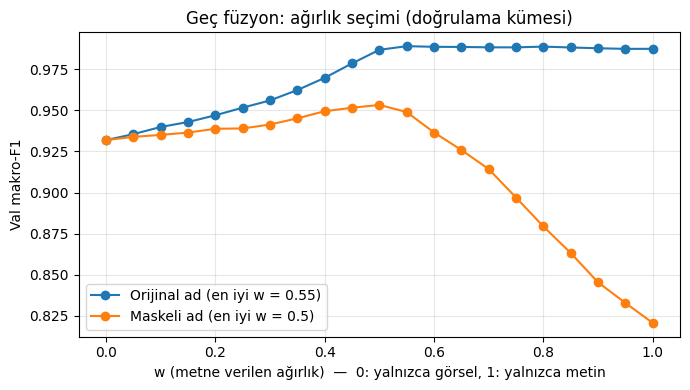

In [15]:
import matplotlib.pyplot as plt

agirliklar = np.round(np.arange(0, 1.0001, 0.05), 2)    # 0.00, 0.05, ..., 1.00

def gec_fuzyon(metin_val, metin_test, ad):
    # her w için val kümesinde makro-F1 hesaplattım
    val_skorlari = []
    for w in agirliklar:
        fuzyon = w * metin_val + (1 - w) * gorsel_olasilik_val
        val_skorlari.append(f1_score(y_val, fuzyon.argmax(1), average="macro"))

    # Val'de en iyi wyi seçtim
    en_iyi_w = agirliklar[int(np.argmax(val_skorlari))]

    # seçilen w ile testi BİR KEZ ölçtüm
    test_fuzyon = en_iyi_w * metin_test + (1 - en_iyi_w) * gorsel_olasilik_test
    test_tahmin = test_fuzyon.argmax(1)
    print(f"{ad}: en iyi w = {en_iyi_w} | val makro-F1 = {max(val_skorlari):.4f} | "
          f"TEST doğruluk = {accuracy_score(y_test, test_tahmin):.4f}, "
          f"TEST makro-F1 = {f1_score(y_test, test_tahmin, average='macro'):.4f}")
    return val_skorlari, en_iyi_w, test_fuzyon

skor_orj, w_orj, gec_test_orj = gec_fuzyon(metin_olasilik_val, metin_olasilik_test, "Orijinal")
skor_msk, w_msk, gec_test_msk = gec_fuzyon(maske_olasilik_val, maske_olasilik_test, "Maskeli ")

# w'ye göre val makro-F1 grafiği çizdirttim
plt.figure(figsize=(7, 4))
plt.plot(agirliklar, skor_orj, marker="o", label=f"Orijinal ad (en iyi w = {w_orj})")
plt.plot(agirliklar, skor_msk, marker="o", label=f"Maskeli ad (en iyi w = {w_msk})")
plt.xlabel("w (metne verilen ağırlık)  —  0: yalnızca görsel, 1: yalnızca metin")
plt.ylabel("Val makro-F1")
plt.title("Geç füzyon: ağırlık seçimi (doğrulama kümesi)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CIKTI}/gec_fuzyon_agirlik.png", dpi=150)
plt.show()


## 4. Ara füzyon
Metni TF-IDF → TruncatedSVD ile 256 boyuta indirdim, görsel gömmeyle birleştirip küçük bir MLP eğittim.

In [16]:
from sklearn.decomposition import TruncatedSVD

# metin özetinin boyutu 256 sütuna sıkıştırcağım
SVD_BOYUT = 256

def metin_ozeti(sutun):
    # tf-idf ve svd sadece train ile öğreniyor, val/test'e sadece uygulanıyor
    # ürün adlarını sayılara çevirdim
    vek = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
    Xtr = vek.fit_transform(train[sutun])          # sözlüğü YALNIZCA train ile öğrendi


    svd = TruncatedSVD(n_components=SVD_BOYUT, random_state=TOHUM)
    Ztr = svd.fit_transform(Xtr)

    # val ve teste aynı kuralları yalnızca uyguladım
    Zva = svd.transform(vek.transform(val[sutun]))
    Zte = svd.transform(vek.transform(test[sutun]))

    # ne kadar sıkıştırdığımızı ve bilginin ne kadarının korunduğunu yazdırdım
    print(f"{sutun}: TF-IDF sütun sayısı = {Xtr.shape[1]} → SVD = {SVD_BOYUT} | "
          f"korunan bilgi (açıklanan varyans) = {svd.explained_variance_ratio_.sum():.1%}")
    return Ztr, Zva, Zte


ozet_orj_train, ozet_orj_val, ozet_orj_test = metin_ozeti("productDisplayName")   # orijinal
ozet_msk_train, ozet_msk_val, ozet_msk_test = metin_ozeti("ad_maskeli")           # maskeli


print("Metin özeti boyutu (train):", ozet_orj_train.shape)


productDisplayName: TF-IDF sütun sayısı = 41680 → SVD = 256 | korunan bilgi (açıklanan varyans) = 74.1%
ad_maskeli: TF-IDF sütun sayısı = 41562 → SVD = 256 | korunan bilgi (açıklanan varyans) = 72.5%
Metin özeti boyutu (train): (23199, 256)


In [17]:
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

def ara_fuzyon(ozet_train, ozet_val, ozet_test, ad):
    #her ürün için görsel özet (1280) + metin özeti (256) → yan yana 1536 sayı
    X_tr = np.hstack([gorsel_gomme_train, ozet_train])
    X_va = np.hstack([gorsel_gomme_val,   ozet_val])
    X_te = np.hstack([gorsel_gomme_test,  ozet_test])

    # ölçekleme: her sütunu ortalama 0, standart sapma 1 olacak şekilde ayarladım
    olcek = StandardScaler().fit(X_tr)
    X_tr, X_va, X_te = olcek.transform(X_tr), olcek.transform(X_va), olcek.transform(X_te)

    # MLP
    keras.utils.set_random_seed(TOHUM)
    mlp = keras.Sequential([
        keras.Input(shape=(X_tr.shape[1],)),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(len(SINIFLAR), activation="softmax"),
    ])
    mlp.compile(optimizer=keras.optimizers.Adam(1e-3),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    #val kaybı 5 tur iyileşmezse durdurdum en iyi ağırlıklara döndü
    erken_dur = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    gecmis = mlp.fit(X_tr, y_train, validation_data=(X_va, y_val),
                     epochs=50, batch_size=128, callbacks=[erken_dur], verbose=0)


    val_tahmin  = mlp.predict(X_va, verbose=0).argmax(1)
    test_olas   = mlp.predict(X_te, verbose=0)
    test_tahmin = test_olas.argmax(1)
    print(f"{ad}: {len(gecmis.epoch)} tur | val makro-F1 = {f1_score(y_val, val_tahmin, average='macro'):.4f} | "
          f"TEST doğruluk = {accuracy_score(y_test, test_tahmin):.4f}, "
          f"TEST makro-F1 = {f1_score(y_test, test_tahmin, average='macro'):.4f}")
    return gecmis, test_olas

gecmis_ara_orj, ara_test_orj = ara_fuzyon(ozet_orj_train, ozet_orj_val, ozet_orj_test, "Orijinal")
gecmis_ara_msk, ara_test_msk = ara_fuzyon(ozet_msk_train, ozet_msk_val, ozet_msk_test, "Maskeli ")


Orijinal: 8 tur | val makro-F1 = 0.9781 | TEST doğruluk = 0.9773, TEST makro-F1 = 0.9755
Maskeli : 7 tur | val makro-F1 = 0.9484 | TEST doğruluk = 0.9395, TEST makro-F1 = 0.9445


## 5. Görselin katkısı
Temel soru: metin zayıfladığında görselin katkısı ne kadar artıyor? Katkı = füzyon − metin tek başına uyguladım

In [18]:
def mf1(olasilik):
    #test olasılıklarından makro-F1 hesaplattım
    return f1_score(y_test, olasilik.argmax(1), average="macro")

katki = pd.DataFrame({
    "Ürün adı":          ["Orijinal", "Maskeli"],
    "Metin tek başına":  [mf1(metin_olasilik_test), mf1(maske_olasilik_test)],
    "Geç füzyon":        [mf1(gec_test_orj),        mf1(gec_test_msk)],
    "Ara füzyon":        [mf1(ara_test_orj),        mf1(ara_test_msk)],
})
# görselin katkısı = füzyon − metin
katki["Katkı (geç, puan)"] = (katki["Geç füzyon"] - katki["Metin tek başına"]) * 100
katki["Katkı (ara, puan)"] = (katki["Ara füzyon"] - katki["Metin tek başına"]) * 100

print(katki.round(4).to_string(index=False))
katki.round(4).to_csv(f"{CIKTI}/gorselin_katkisi.csv", index=False)


Ürün adı  Metin tek başına  Geç füzyon  Ara füzyon  Katkı (geç, puan)  Katkı (ara, puan)
Orijinal            0.9821      0.9850      0.9755             0.2965            -0.6543
 Maskeli            0.8172      0.9535      0.9445            13.6213            12.7241


## 6. Hata analizi (en iyi model: geç füzyon, orijinal ad)
### 6.1 Normalize karışıklık matrisi

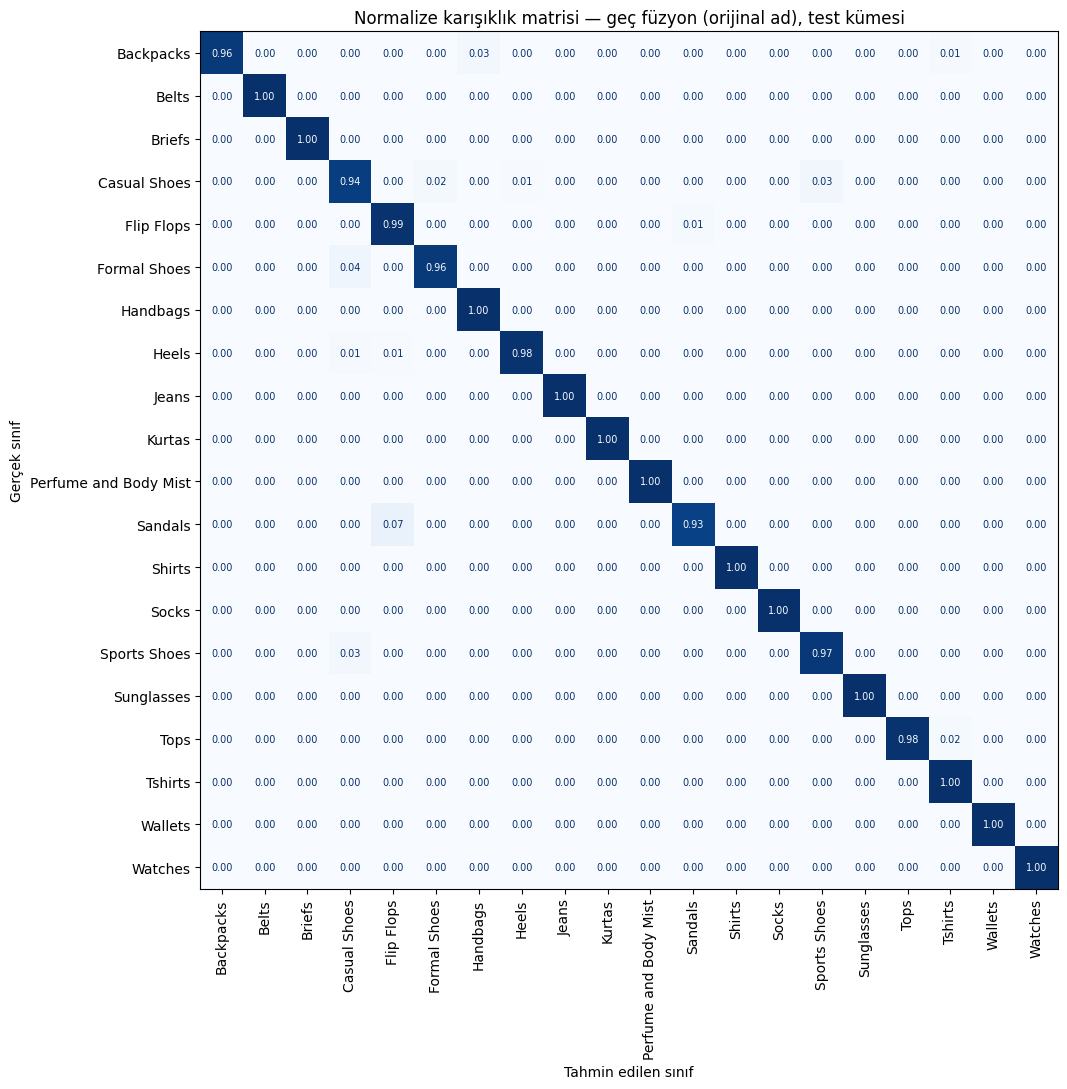

Yanlış tahmin sayısı: 64 / 4972


In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# en iyi model: geç füzyon (orijinal adlar)
en_iyi_tahmin = gec_test_orj.argmax(1)

km = confusion_matrix(y_test, en_iyi_tahmin, normalize="true")

fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay(km, display_labels=SINIFLAR).plot(
    ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=90, colorbar=False)
ax.set_title("Normalize karışıklık matrisi — geç füzyon (orijinal ad), test kümesi")
ax.set_xlabel("Tahmin edilen sınıf")
ax.set_ylabel("Gerçek sınıf")
for metin in ax.texts:
    metin.set_fontsize(7)
plt.tight_layout()
plt.savefig(f"{CIKTI}/karisiklik_matrisi.png", dpi=150)
plt.show()

print("Yanlış tahmin sayısı:", (en_iyi_tahmin != y_test).sum(), "/", len(y_test))


In [20]:
print(classification_report(y_test, en_iyi_tahmin, target_names=SINIFLAR, digits=3))


                       precision    recall  f1-score   support

            Backpacks      1.000     0.963     0.981       108
                Belts      1.000     1.000     1.000       122
               Briefs      1.000     1.000     1.000       127
         Casual Shoes      0.964     0.941     0.953       427
           Flip Flops      0.925     0.986     0.954       138
         Formal Shoes      0.919     0.958     0.938        95
             Handbags      0.989     0.996     0.992       264
                Heels      0.985     0.985     0.985       198
                Jeans      1.000     1.000     1.000        91
               Kurtas      1.000     0.996     0.998       277
Perfume and Body Mist      0.989     1.000     0.995        91
              Sandals      0.984     0.933     0.958       134
               Shirts      1.000     1.000     1.000       482
                Socks      1.000     1.000     1.000       103
         Sports Shoes      0.955     0.967     0.961  

### 6.2 En çok karışan 5 sınıf çifti

In [21]:
#normalize edilmemiş karışıklık matrisi:
#hücrelerde ürün sayıları olacak
km_sayi = confusion_matrix(y_test, en_iyi_tahmin)

# her karışıklığı bir listeye topladım
ciftler = []
for g in range(len(SINIFLAR)):            # g: gerçek sınıfın numarası (satır)
    for t in range(len(SINIFLAR)):        # t: tahmin edilen sınıfın numarası (sütun)
        if g != t and km_sayi[g, t] > 0:
            ciftler.append({
                "Gerçek sınıf": SINIFLAR[g],
                "Tahmin": SINIFLAR[t],
                "Sayı": km_sayi[g, t],
                "Oran (gerçek sınıf içinde)": round(km_sayi[g, t] / km_sayi[g].sum(), 3),
            })

# sayıya göre büyükten küçüğe sıraladım ilk 5 satır = en çok karışan 5 çift
ciftler = pd.DataFrame(ciftler).sort_values("Sayı", ascending=False)
print("Toplam yanlış tahmin:", ciftler["Sayı"].sum())
print(ciftler.head(5).to_string(index=False))

# raporda kullanılacak ilk 5 çift
ciftler.head(5).to_csv(f"{CIKTI}/karisan_ciftler_ilk5.csv", index=False)
# bütün karışıklık listesi
ciftler.to_csv(f"{CIKTI}/karisan_ciftler.csv", index=False)


Toplam yanlış tahmin: 64
Gerçek sınıf       Tahmin  Sayı  Oran (gerçek sınıf içinde)
Casual Shoes Sports Shoes    14                       0.033
     Sandals   Flip Flops     9                       0.067
Sports Shoes Casual Shoes     9                       0.029
Casual Shoes Formal Shoes     8                       0.019
Formal Shoes Casual Shoes     4                       0.042


### 6.3 Yanlış tahmin örnekleri
Modelin en emin olduğu 16 hatayı seçtim. Model çok emin olup yanılıyorsa bu çoğu zaman etiket hatasına işaret ediyor.

In [22]:
import kagglehub
import textwrap
from PIL import Image

veri_yolu = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

# test tablosuna tahmini ve modelin ne kadar emin olduğunu ekledim
yanlis = test.copy()
yanlis["tahmin"] = [SINIFLAR[i] for i in en_iyi_tahmin]
yanlis["guven"] = gec_test_orj.max(axis=1)                 # en yüksek olasılık = eminlik

# sadece hatalar, en emin olunandan en aza
yanlis = yanlis[en_iyi_tahmin != y_test].sort_values("guven", ascending=False)

print(yanlis.head(16)[["id", "productDisplayName", "articleType", "tahmin", "guven"]].to_string(index=False))


Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
   id                                  productDisplayName  articleType       tahmin    guven
 9116              Puma Women Ikonis 2 White Sports Shoes Casual Shoes Sports Shoes 0.996574
44473                           Gliders Women Black Shoes Sports Shoes Casual Shoes 0.958675
53779                            Puma Women Black T-shirt         Tops      Tshirts 0.919044
 5271                  Wildcraft Unisex Green Holster Bag    Backpacks     Handbags 0.899837
16248                   Crocs Patricia Women Black Sandal   Flip Flops      Sandals 0.879907
 7429            W Women's Round Neck Sleeveless Pink Top       Kurtas         Tops 0.872263
15409                        Fila Men Cage Black Slippers      Sandals   Flip Flops 0.868584
15853 Warner Bros Kids Girls TW Love flops Green Slippers      Sandals   Flip Flops 0.864365
38528                        Puma Men White Caliber Shoes Casual Shoes Sports Sh

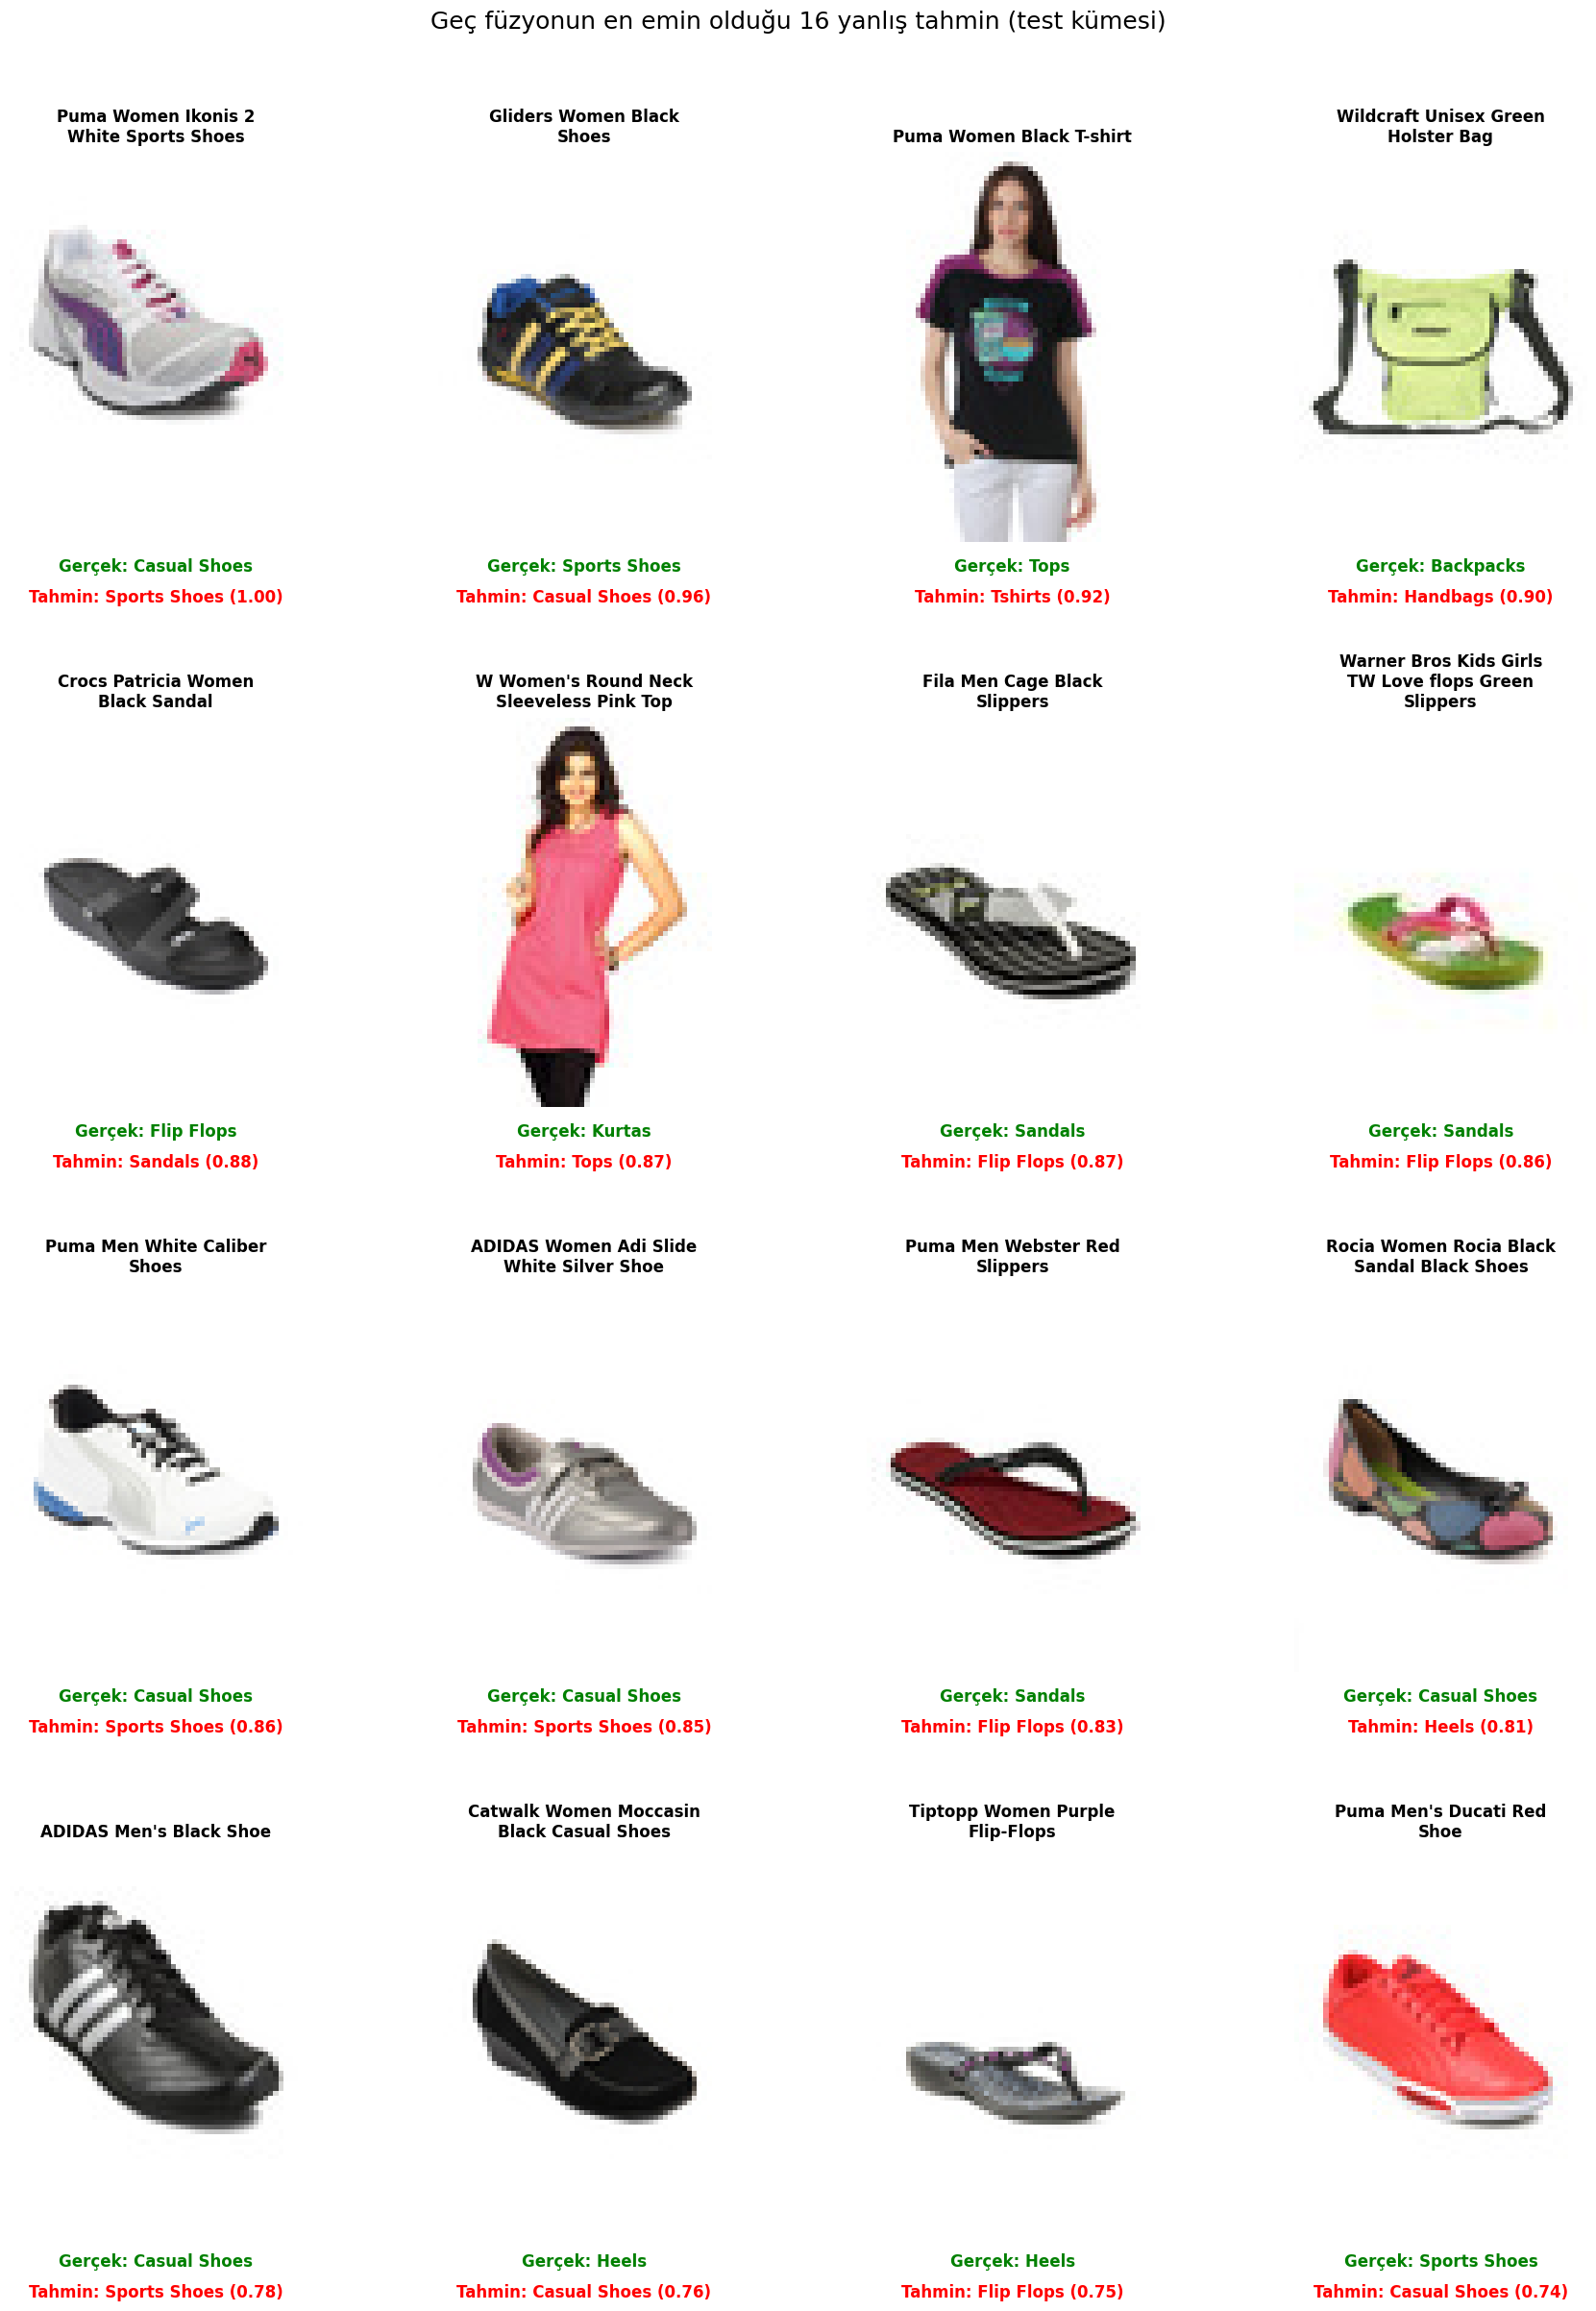

In [23]:
# daha okunabilir olan bir tablo da görseller ile hazırladım
fig, eksenler = plt.subplots(4, 4, figsize=(18, 24))
for eksen, (_, satir) in zip(eksenler.flat, yanlis.head(16).iterrows()):
    eksen.imshow(Image.open(f"{veri_yolu}/images/{satir['id']}.jpg"))
    eksen.axis("off")
    # üstte ürün adı altında gerçek sınıf (yeşil) ve tahmin (kırmızı)
    eksen.set_title(textwrap.fill(satir["productDisplayName"], 24),
                    fontsize=12, fontweight="bold", pad=8)
    eksen.text(0.5, -0.04, f"Gerçek: {satir['articleType']}", transform=eksen.transAxes,
               ha="center", va="top", fontsize=12, color="green", fontweight="bold")
    eksen.text(0.5, -0.12, f"Tahmin: {satir['tahmin']} ({satir['guven']:.2f})", transform=eksen.transAxes,
               ha="center", va="top", fontsize=12, color="red", fontweight="bold")

plt.suptitle("Geç füzyonun en emin olduğu 16 yanlış tahmin (test kümesi)", fontsize=18, y=1.0)
plt.tight_layout(rect=[0, 0, 1, 0.98])                  # üst başlık için yer bırak
plt.subplots_adjust(hspace=0.45)                         # satırlar arasında boşluk
plt.savefig(f"{CIKTI}/yanlis_ornekler2.png", dpi=150, bbox_inches="tight")
plt.show()


### 6.4 Hata kaynakları (64 hatanın tamamı)
Ürün adında tahmin edilen ya da gerçek sınıfın kelimesi geçiyor mu diye baktım.

In [24]:
import re

# her sınıfın adını oluşturan kelimeler
sinif_kelimeleri = {
    "Backpacks": ["backpack"], "Belts": ["belt"], "Briefs": ["brief"],
    "Casual Shoes": ["casual"], "Flip Flops": ["flip", "flop"], "Formal Shoes": ["formal"],
    "Handbags": ["handbag"], "Heels": ["heel"], "Jeans": ["jean"], "Kurtas": ["kurta"],
    "Perfume and Body Mist": ["perfume", "mist"], "Sandals": ["sandal"],
    "Shirts": ["shirt"], "Socks": ["sock"], "Sports Shoes": ["sport"],
    "Sunglasses": ["sunglass"], "Tops": ["top"], "Tshirts": ["t-shirt", "tshirt"],
    "Wallets": ["wallet"], "Watches": ["watch"],
}

def adda_gecer_mi(ad, sinif):
    for kelime in sinif_kelimeleri[sinif]:
        desen = rf"\b{re.escape(kelime)}(s|es)?\b"
        if sinif == "Shirts":
            desen = r"(?<!t-)" + desen
        if re.search(desen, ad, re.IGNORECASE):
            return True
    return False

def hata_kaynagi(satir):
    tahmin_var = adda_gecer_mi(satir["productDisplayName"], satir["tahmin"])
    gercek_var = adda_gecer_mi(satir["productDisplayName"], satir["articleType"])
    if tahmin_var and gercek_var:
        return "Çelişkili başlık (iki sınıf da geçiyor)"
    if tahmin_var:
        return "Olası etiket hatası (başlık tahmini destekliyor)"
    if gercek_var:
        return "Model hatası (başlık gerçek sınıfı söylüyor)"
    return "Yetersiz başlık (tür bilgisi yok)"

yanlis["hata_kaynagi"] = yanlis.apply(hata_kaynagi, axis=1)

# her kaynaktan kaç hata var?
ozet = yanlis["hata_kaynagi"].value_counts()
print(ozet.to_string())
print("\nToplam:", ozet.sum())

# her gruptan birkaç örnek
for kaynak in ozet.index:
    print(f"\n--- {kaynak} ---")
    print(yanlis[yanlis["hata_kaynagi"] == kaynak][["productDisplayName", "articleType", "tahmin"]]
          .head(4).to_string(index=False))

yanlis.to_csv(f"{CIKTI}/yanlis_tahminler.csv", index=False)


hata_kaynagi
Yetersiz başlık (tür bilgisi yok)                   50
Olası etiket hatası (başlık tahmini destekliyor)    11
Model hatası (başlık gerçek sınıfı söylüyor)         2
Çelişkili başlık (iki sınıf da geçiyor)              1

Toplam: 64

--- Yetersiz başlık (tür bilgisi yok) ---
                productDisplayName  articleType       tahmin
         Gliders Women Black Shoes Sports Shoes Casual Shoes
Wildcraft Unisex Green Holster Bag    Backpacks     Handbags
      Fila Men Cage Black Slippers      Sandals   Flip Flops
      Puma Men White Caliber Shoes Casual Shoes Sports Shoes

--- Olası etiket hatası (başlık tahmini destekliyor) ---
                      productDisplayName  articleType       tahmin
  Puma Women Ikonis 2 White Sports Shoes Casual Shoes Sports Shoes
                Puma Women Black T-shirt         Tops      Tshirts
       Crocs Patricia Women Black Sandal   Flip Flops      Sandals
W Women's Round Neck Sleeveless Pink Top       Kurtas         Tops

--- Model hat